In [1]:
import kagglehub
path = kagglehub.dataset_download("shashwatwork/consume-complaints-dataset-fo-nlp")

Using Colab cache for faster access to the 'consume-complaints-dataset-fo-nlp' dataset.


In [8]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout

In [45]:
df = pd.read_csv(path + "/complaints_processed.csv")
print(df.columns)
df.head()

Index(['Unnamed: 0', 'product', 'narrative'], dtype='object')


,Unnamed: 0,product,narrative
0,0,credit_card,purchase order day shipping amount receive pro...
1,1,credit_card,forwarded message date tue subject please inve...
2,2,retail_banking,forwarded message cc sent friday pdt subject f...
3,3,credit_reporting,payment history missing credit report speciali...
4,4,credit_reporting,payment history missing credit report made mis...


In [11]:
df = df[["narrative", "product"]]
df.columns = ["text", "label"]
df = df.dropna()

print(df.shape)
df.head()


(162411, 2)


,text,label
0,purchase order day shipping amount receive pro...,credit_card
1,forwarded message date tue subject please inve...,credit_card
2,forwarded message cc sent friday pdt subject f...,retail_banking
3,payment history missing credit report speciali...,credit_reporting
4,payment history missing credit report made mis...,credit_reporting


label
credit_reporting       91172
debt_collection        23148
mortgages_and_loans    18990
credit_card            15566
retail_banking         13535
Name: count, dtype: int64


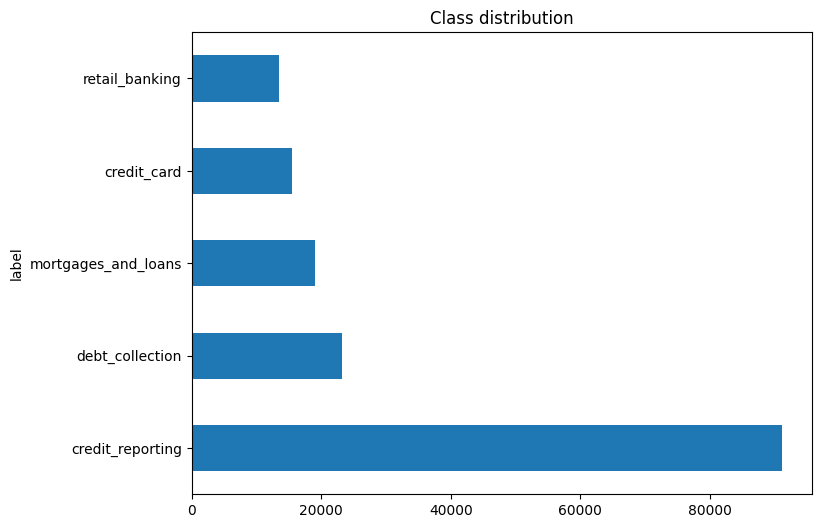

In [12]:
print(df["label"].value_counts())

df["label"].value_counts().plot(kind="barh", figsize=(8, 6))
plt.title("Class distribution")
plt.show()

In [13]:
top6 = df["label"].value_counts().head(6).index
df = df[df["label"].isin(top6)]

df = df.sample(frac=1, random_state=42)
df = df.groupby("label").head(7000)

print(df["label"].value_counts())
print(df.shape)

label
mortgages_and_loans    7000
credit_reporting       7000
debt_collection        7000
credit_card            7000
retail_banking         7000
Name: count, dtype: int64
(35000, 2)


In [14]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"x{2,}", " ", text)
    text = re.sub(r"http\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_text"] = df["text"].apply(clean_text)
print(df["text"].iloc[0][:200])
print(df["clean_text"].iloc[0][:200])

called acima ask bill hold payment told date put block account needed call restart payment send mail sent eft bank amount told would plus bank fee kept going follows ask bank stop acima said could cal
called acima ask bill hold payment told date put block account needed call restart payment send mail sent eft bank amount told would plus bank fee kept going follows ask bank stop acima said could cal


In [15]:
le = LabelEncoder()
df["label_id"] = le.fit_transform(df["label"])

class_names = list(le.classes_)
num_classes = len(class_names)
print(class_names)

['credit_card', 'credit_reporting', 'debt_collection', 'mortgages_and_loans', 'retail_banking']


In [16]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["label_id"])

print(train_df.shape)
print(test_df.shape)

(28000, 4)
(7000, 4)


In [17]:
weights = compute_class_weight("balanced", classes=np.unique(train_df["label_id"]), y=train_df["label_id"])
class_weights = dict(enumerate(weights))
print(class_weights)

{0: np.float64(1.0), 1: np.float64(1.0), 2: np.float64(1.0), 3: np.float64(1.0), 4: np.float64(1.0)}


In [18]:
max_words = 10000

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(train_df["clean_text"])

X_train_seq = tokenizer.texts_to_sequences(train_df["clean_text"])
X_test_seq = tokenizer.texts_to_sequences(test_df["clean_text"])

print(train_df["clean_text"].iloc[0][:100])
print(X_train_seq[0][:15])

hello recently signed free experian credit boost showed current credit score little asked wanted boo
[945, 366, 285, 718, 379, 3, 3784, 548, 240, 3, 157, 920, 51, 367, 3784]


In [19]:
lengths = [len(s) for s in X_train_seq]
print("average length:", np.mean(lengths))
print("95 percentile:", np.percentile(lengths, 95))

average length: 90.974
95 percentile: 262.0


In [20]:
max_len = 200

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding="post", truncating="post")
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len, padding="post", truncating="post")

y_train = train_df["label_id"].values
y_test = test_df["label_id"].values

print(X_train_pad.shape)
print(X_test_pad.shape)

(28000, 200)
(7000, 200)


In [21]:
results = []

def evaluate_model(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="weighted")
    rec = recall_score(y_true, y_pred, average="weighted")
    f1 = f1_score(y_true, y_pred, average="weighted")

    print(name)
    print("Accuracy :", round(acc, 4))
    print("Precision:", round(prec, 4))
    print("Recall   :", round(rec, 4))
    print("F1-score :", round(f1, 4))
    print()
    print(classification_report(y_true, y_pred, target_names=class_names))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.title("Confusion Matrix - " + name)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    results.append({"Model": name, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1-score": f1})

In [22]:
model_rnn = Sequential([
    Embedding(max_words, 100),
    SimpleRNN(64),
    Dropout(0.3),
    Dense(num_classes, activation="softmax")
])

model_rnn.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model_rnn.build(input_shape=(None, max_len))
model_rnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 100)       │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │        10,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,010,885 (3.86 MB)

 Trainable params: 1,010,885 (3.86 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
history_rnn = model_rnn.fit(
    X_train_pad, y_train,
    validation_split=0.1,
    epochs=12,
    batch_size=128,
    class_weight=class_weights
)

Epoch 1/12
197/197 ━━━━━━━━━━━━━━━━━━━━ 7s 37ms/step - accuracy: 0.3048 - loss: 1.4601 - val_accuracy: 0.2175 - val_loss: 1.6267
Epoch 2/12
197/197 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.3115 - loss: 1.4455 - val_accuracy: 0.2311 - val_loss: 1.6343
Epoch 3/12
197/197 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.3078 - loss: 1.4483 - val_accuracy: 0.2179 - val_loss: 1.6324
Epoch 4/12
197/197 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.3060 - loss: 1.4449 - val_accuracy: 0.2329 - val_loss: 1.6479
Epoch 5/12
197/197 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.3101 - loss: 1.4375 - val_accuracy: 0.2411 - val_loss: 1.6582
Epoch 6/12
197/197 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.3171 - loss: 1.4335 - val_accuracy: 0.2207 - val_loss: 1.6704
Epoch 7/12
197/197 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.3210 - loss: 1.4282 - val_accuracy: 0.2075 - val_loss: 1.7123
Epoch 8/12
197/197 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.3124 - loss: 1.4371 - val_accu

219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
SimpleRNN
Accuracy : 0.2237
Precision: 0.2435
Recall   : 0.2237
F1-score : 0.1938

                     precision    recall  f1-score   support

        credit_card       0.19      0.42      0.26      1400
   credit_reporting       0.25      0.43      0.32      1400
    debt_collection       0.24      0.05      0.09      1400
mortgages_and_loans       0.33      0.10      0.16      1400
     retail_banking       0.20      0.11      0.14      1400

           accuracy                           0.22      7000
          macro avg       0.24      0.22      0.19      7000
       weighted avg       0.24      0.22      0.19      7000



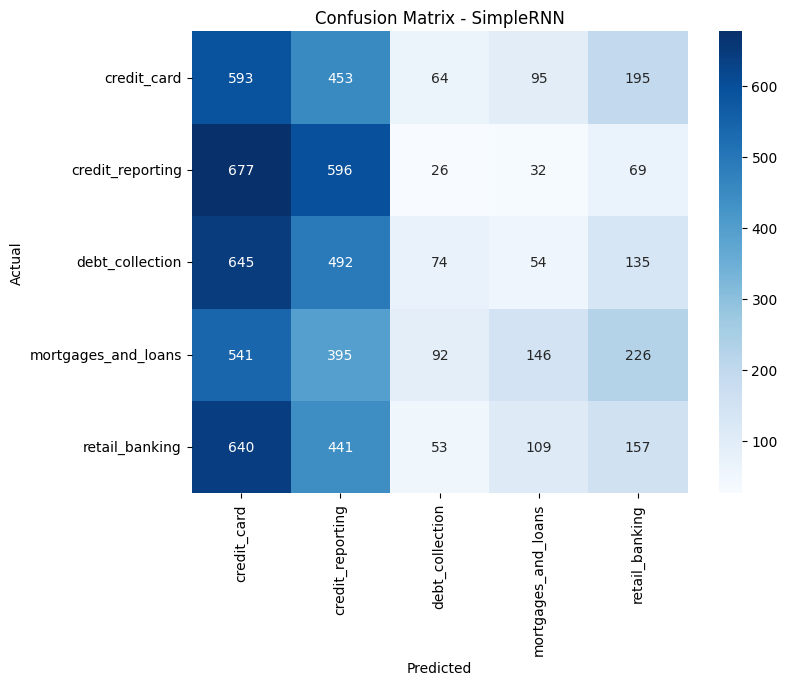

In [25]:
y_pred_rnn = np.argmax(model_rnn.predict(X_test_pad), axis=1)
evaluate_model("SimpleRNN", y_test, y_pred_rnn)

In [26]:
model_lstm = Sequential([
    Embedding(max_words, 100),
    LSTM(64),
    Dropout(0.3),
    Dense(num_classes, activation="softmax")
])

model_lstm.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model_lstm.build(input_shape=(None, max_len))
model_lstm.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 100)       │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,042,565 (3.98 MB)

 Trainable params: 1,042,565 (3.98 MB)

 Non-trainable params: 0 (0.00 B)

In [27]:
history_lstm = model_lstm.fit(
    X_train_pad, y_train,
    validation_split=0.1,
    epochs=12,
    batch_size=128,
    class_weight=class_weights
)

Epoch 1/12
197/197 ━━━━━━━━━━━━━━━━━━━━ 14s 21ms/step - accuracy: 0.2191 - loss: 1.6277 - val_accuracy: 0.2325 - val_loss: 1.6038
Epoch 2/12
197/197 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.2366 - loss: 1.5975 - val_accuracy: 0.2211 - val_loss: 1.5855
Epoch 3/12
197/197 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.2403 - loss: 1.5646 - val_accuracy: 0.2282 - val_loss: 1.5583
Epoch 4/12
197/197 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.2964 - loss: 1.4773 - val_accuracy: 0.4800 - val_loss: 1.2008
Epoch 5/12
197/197 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.4750 - loss: 1.1517 - val_accuracy: 0.3593 - val_loss: 1.3364
Epoch 6/12
197/197 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.5017 - loss: 1.1338 - val_accuracy: 0.6107 - val_loss: 0.9480
Epoch 7/12
197/197 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.5470 - loss: 1.0138 - val_accuracy: 0.6129 - val_loss: 0.8988
Epoch 8/12
197/197 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.6596 - loss: 0.8367 - val_acc

219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
LSTM
Accuracy : 0.8183
Precision: 0.8195
Recall   : 0.8183
F1-score : 0.8177

                     precision    recall  f1-score   support

        credit_card       0.81      0.74      0.78      1400
   credit_reporting       0.76      0.82      0.79      1400
    debt_collection       0.86      0.77      0.81      1400
mortgages_and_loans       0.83      0.89      0.85      1400
     retail_banking       0.84      0.87      0.86      1400

           accuracy                           0.82      7000
          macro avg       0.82      0.82      0.82      7000
       weighted avg       0.82      0.82      0.82      7000



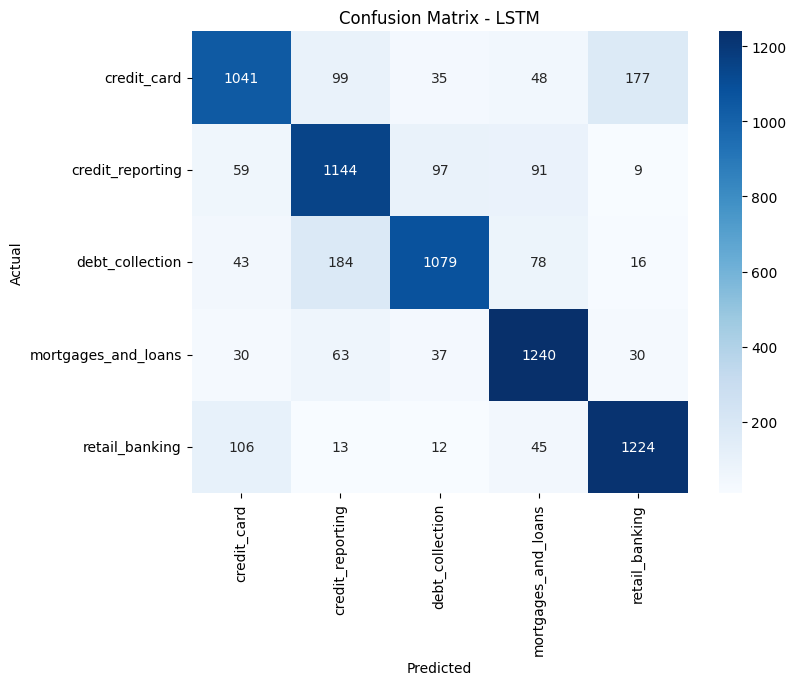

In [28]:
y_pred_lstm = np.argmax(model_lstm.predict(X_test_pad), axis=1)
evaluate_model("LSTM", y_test, y_pred_lstm)

In [29]:
model_gru = Sequential([
    Embedding(max_words, 100),
    GRU(64),
    Dropout(0.3),
    Dense(num_classes, activation="softmax")
])

model_gru.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model_gru.build(input_shape=(None, max_len))
model_gru.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 200, 100)       │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        31,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,032,197 (3.94 MB)

 Trainable params: 1,032,197 (3.94 MB)

 Non-trainable params: 0 (0.00 B)

In [30]:
history_gru = model_gru.fit(
    X_train_pad, y_train,
    validation_split=0.1,
    epochs=12,
    batch_size=128,
    class_weight=class_weights
)

Epoch 1/12
197/197 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - accuracy: 0.2187 - loss: 1.6057 - val_accuracy: 0.2357 - val_loss: 1.5982
Epoch 2/12
197/197 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.2697 - loss: 1.5312 - val_accuracy: 0.3436 - val_loss: 1.3846
Epoch 3/12
197/197 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.3492 - loss: 1.3785 - val_accuracy: 0.2839 - val_loss: 1.4970
Epoch 4/12
197/197 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.3419 - loss: 1.3865 - val_accuracy: 0.3639 - val_loss: 1.3605
Epoch 5/12
197/197 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.4558 - loss: 1.2347 - val_accuracy: 0.5046 - val_loss: 1.0016
Epoch 6/12
197/197 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.5442 - loss: 0.9804 - val_accuracy: 0.5421 - val_loss: 0.9387
Epoch 7/12
197/197 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.6244 - loss: 0.8561 - val_accuracy: 0.6321 - val_loss: 0.8972
Epoch 8/12
197/197 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.6847 - loss: 0.7839 - val_accu

219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
GRU
Accuracy : 0.811
Precision: 0.8124
Recall   : 0.811
F1-score : 0.8112

                     precision    recall  f1-score   support

        credit_card       0.77      0.79      0.78      1400
   credit_reporting       0.75      0.79      0.77      1400
    debt_collection       0.82      0.77      0.79      1400
mortgages_and_loans       0.87      0.83      0.85      1400
     retail_banking       0.85      0.88      0.86      1400

           accuracy                           0.81      7000
          macro avg       0.81      0.81      0.81      7000
       weighted avg       0.81      0.81      0.81      7000



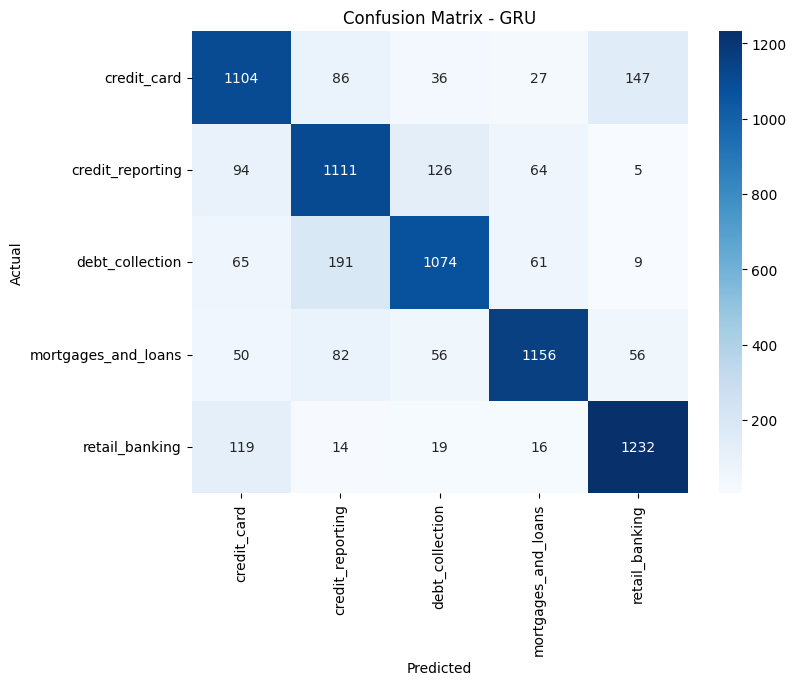

In [31]:
y_pred_gru = np.argmax(model_gru.predict(X_test_pad), axis=1)
evaluate_model("GRU", y_test, y_pred_gru)

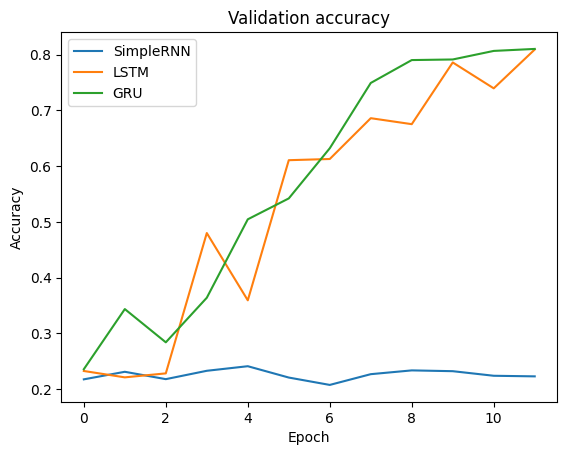

In [32]:
plt.plot(history_rnn.history["val_accuracy"], label="SimpleRNN")
plt.plot(history_lstm.history["val_accuracy"], label="LSTM")
plt.plot(history_gru.history["val_accuracy"], label="GRU")
plt.title("Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [33]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments

model_name = "distilbert-base-uncased"
hf_tokenizer = AutoTokenizer.from_pretrained(model_name)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [36]:
class ComplaintDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels):
        self.encodings = hf_tokenizer(list(texts), truncation=True, padding=True, max_length=128)
        self.labels = list(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        item = {key: torch.tensor(val[i]) for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[i])
        return item

train_dataset = ComplaintDataset(train_df["text"], train_df["label_id"])
test_dataset = ComplaintDataset(test_df["text"], test_df["label_id"])
print(len(train_dataset), len(test_dataset))

28000 7000


In [35]:
hf_model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=num_classes)

training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    logging_steps=200,
    save_strategy="no",
    report_to="none"
)

trainer = Trainer(model=hf_model, args=training_args, train_dataset=train_dataset)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [37]:
trainer.train()

Step,Training Loss
200,1.001079
400,0.642717
600,0.591398
800,0.567124
1000,0.554458
1200,0.520418
1400,0.512549
1600,0.505490
1800,0.453243
2000,0.386933


TrainOutput(global_step=3500, training_loss=0.49787137712751117, metrics={'train_runtime': 664.1507, 'train_samples_per_second': 84.318, 'train_steps_per_second': 5.27, 'total_flos': 1854642800640000.0, 'train_loss': 0.49787137712751117, 'epoch': 2.0})

DistilBERT
Accuracy : 0.8593
Precision: 0.8592
Recall   : 0.8593
F1-score : 0.8591

                     precision    recall  f1-score   support

        credit_card       0.83      0.85      0.84      1400
   credit_reporting       0.83      0.83      0.83      1400
    debt_collection       0.85      0.82      0.83      1400
mortgages_and_loans       0.90      0.89      0.89      1400
     retail_banking       0.89      0.92      0.91      1400

           accuracy                           0.86      7000
          macro avg       0.86      0.86      0.86      7000
       weighted avg       0.86      0.86      0.86      7000



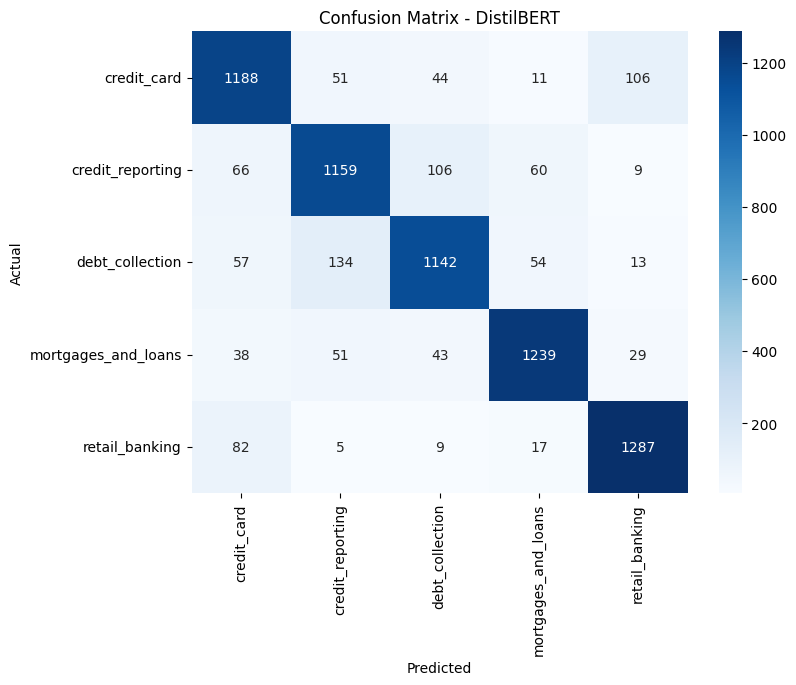

In [38]:
output = trainer.predict(test_dataset)
y_pred_bert = np.argmax(output.predictions, axis=1)
evaluate_model("DistilBERT", y_test, y_pred_bert)

In [39]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values("F1-score", ascending=False).reset_index(drop=True)
results_df

,Model,Accuracy,Precision,Recall,F1-score
0,DistilBERT,0.859286,0.859240,0.859286,0.859122
1,LSTM,0.818286,0.819527,0.818286,0.817662
2,GRU,0.811000,0.812435,0.811000,0.811213
3,SimpleRNN,0.223714,0.243477,0.223714,0.193786


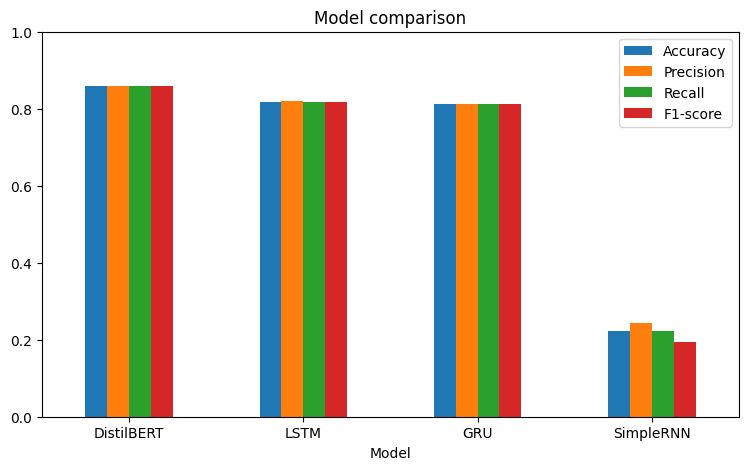

Best model: DistilBERT


In [40]:
results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score"]].plot(kind="bar", figsize=(9, 5))
plt.title("Model comparison")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

best_name = results_df.loc[0, "Model"]
print("Best model:", best_name)

In [41]:
def predict_complaint(text):
    if best_name == "DistilBERT":
        inputs = hf_tokenizer(text, return_tensors="pt", truncation=True, max_length=128)
        inputs = {k: v.to(trainer.model.device) for k, v in inputs.items()}
        with torch.no_grad():
            logits = trainer.model(**inputs).logits
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()
    else:
        models = {"SimpleRNN": model_rnn, "LSTM": model_lstm, "GRU": model_gru}
        seq = tokenizer.texts_to_sequences([clean_text(text)])
        pad = pad_sequences(seq, maxlen=max_len, padding="post", truncating="post")
        probs = models[best_name].predict(pad, verbose=0)[0]

    index = int(np.argmax(probs))
    return class_names[index], float(probs[index])

In [42]:
new_complaints = [
    "They keep calling me every day about a debt that I already paid.",
    "There is a charge on my credit card that I never made and the bank will not remove it.",
    "My mortgage company lost my payment and now they say I am late.",
    "I found a wrong account on my credit report and the bureau refuses to fix it."
]

for c in new_complaints:
    label, conf = predict_complaint(c)
    print(c)
    print("->", label, "| confidence:", round(conf, 3))
    print()

They keep calling me every day about a debt that I already paid.
-> debt_collection | confidence: 0.929

There is a charge on my credit card that I never made and the bank will not remove it.
-> credit_card | confidence: 0.886

My mortgage company lost my payment and now they say I am late.
-> mortgages_and_loans | confidence: 0.964

I found a wrong account on my credit report and the bureau refuses to fix it.
-> credit_reporting | confidence: 0.803



In [43]:
!pip install -q gradio

In [44]:
import gradio as gr

def gradio_predict(text):
    if text.strip() == "":
        return "Please write a complaint", ""
    label, conf = predict_complaint(text)
    return label, str(round(conf * 100, 2)) + " %"

demo = gr.Interface(
    fn=gradio_predict,
    inputs=gr.Textbox(lines=6, label="Complaint narrative"),
    outputs=[gr.Textbox(label="Predicted category"), gr.Textbox(label="Confidence score")],
    title="Consumer Complaint Classifier",
    description="Write a customer complaint and the model will predict its category."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8436899bdc246ebb0f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
